# Estudio 4 — Lo mínimo que necesitan los peces y qué es sensible

**Preguntas:**

1. ¿Qué reglas son imprescindibles para que haya cardumen?
2. ¿Qué parámetros cambian mucho el comportamiento (sensibles) y cuáles casi no?
3. ¿Cuál es el modelo más simple que sigue funcionando?

El plan completo está en el [README](README.md).

## Preparación

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the parameter_studies folder (the one with study_tools.py) and let Python import from it.
TOOLS_FOLDER = Path.cwd()
while not (TOOLS_FOLDER / "study_tools.py").is_file():
    if TOOLS_FOLDER == TOOLS_FOLDER.parent:
        raise FileNotFoundError("study_tools.py was not found in this folder or any parent folder.")
    TOOLS_FOLDER = TOOLS_FOLDER.parent
if str(TOOLS_FOLDER) not in sys.path:
    sys.path.insert(0, str(TOOLS_FOLDER))

import study_tools
from study_tools import (
    A0_SETTINGS, PUCKETT_SETTINGS, A0_COLOR, PUCKETT_COLOR, EXTRA_COLOR,
    change_settings, final_label_counts, run_many, short_table, summarize,
)

# Where this study keeps its results and figures.
STUDY_FOLDER = TOOLS_FOLDER / "04_minimo_y_sensibilidad"
DATA_FOLDER = STUDY_FOLDER / "data"
FIGURE_FOLDER = STUDY_FOLDER / "figures"
DATA_FOLDER.mkdir(exist_ok=True)
FIGURE_FOLDER.mkdir(exist_ok=True)

SEEDS = list(range(10))
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

## Parte A — Quitar reglas

Usamos A0 (nuestro modelo) y A4 (Puckett) y apagamos reglas.

**Ojo con un detalle del modelo:** apagar una regla **no** cambia las zonas. Si apagamos la orientación, la zona de 0.5 a 3 BL queda "muda": un vecino ahí no provoca ninguna reacción, y la atracción sigue empezando en 3 BL. Por eso agregamos dos filas extra (no están en el README) **sin ese hueco**: r_o = 0.51 BL, así que la atracción empieza justo después de la repulsión, como el "swarm" de Couzin.

In [2]:
RULE_SETS = [
    ("las tres", "repulsion+orientation+attraction"),
    ("repulsión + atracción", "repulsion+attraction"),
    ("repulsión + orientación", "repulsion+orientation"),
    ("orientación + atracción", "orientation+attraction"),
    ("solo atracción", "attraction"),
    ("ninguna", "none"),
]

rule_runs = []
for base in [A0_SETTINGS, PUCKETT_SETTINGS]:
    for name, rules in RULE_SETS:
        settings = change_settings(base, f"{base['base']}: {name}", {"rules": rules})
        settings["rule_set"] = name
        rule_runs.append(settings)

# Extra rows: no silent gap between the repulsion and the attraction zone.
NO_GAP_ORIENTATION_RADIUS = 0.51
no_gap_runs = []
for base in [A0_SETTINGS, PUCKETT_SETTINGS]:
    for name, rules in [("repulsión + atracción, sin hueco", "repulsion+attraction"),
                        ("solo atracción, sin hueco", "attraction")]:
        changes = {"rules": rules, "orientation_radius": NO_GAP_ORIENTATION_RADIUS}
        settings = change_settings(base, f"{base['base']}: {name}", changes)
        settings["rule_set"] = name
        no_gap_runs.append(settings)

print(len(rule_runs), "rule sets from the README +", len(no_gap_runs), "extra rows")

12 rule sets from the README + 4 extra rows


Corremos las 12 configuraciones del README y las 4 extra, con 10 seeds cada una.

In [3]:
rule_results = run_many(rule_runs, SEEDS, DATA_FOLDER / "part_a_rules.csv")
no_gap_results = run_many(no_gap_runs, SEEDS, DATA_FOLDER / "part_a_rules_no_gap.csv")
rules_all = pd.concat([rule_results, no_gap_results], ignore_index=True)
rules_summary = summarize(rules_all, ["label", "base", "rule_set"])

Loaded saved results from part_a_rules.csv (set study_tools.RERUN = True to simulate again).
Loaded saved results from part_a_rules_no_gap.csv (set study_tools.RERUN = True to simulate again).


### Resultados de la parte A

In [4]:
short_table(rules_summary)

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,A0: las tres,10/10,0.95 ± 0.00,0.03 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.00
1,A0: repulsión + atracción,0/10,0.12 ± 0.00,0.07 ± 0.00,0.67 ± 0.03,0.31 ± 0.14,0.00 ± 0.00,0.26 ± 0.00
2,A0: repulsión + orientación,10/10,0.96 ± 0.00,0.04 ± 0.02,0.63 ± 0.04,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
3,A0: orientación + atracción,0/10,0.99 ± 0.00,0.12 ± 0.05,0.07 ± 0.01,1.00 ± 0.00,1.00 ± 0.00,0.00 ± 0.00
4,A0: solo atracción,0/10,0.17 ± 0.02,0.11 ± 0.02,0.22 ± 0.02,0.10 ± 0.10,1.00 ± 0.00,0.00 ± 0.00
5,A0: ninguna,0/10,0.21 ± 0.02,0.14 ± 0.01,2.47 ± 0.03,0.22 ± 0.03,0.08 ± 0.01,0.05 ± 0.01
6,A4: las tres,6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
7,A4: repulsión + atracción,0/10,0.34 ± 0.03,0.23 ± 0.02,1.59 ± 0.09,0.06 ± 0.04,0.00 ± 0.00,0.25 ± 0.00
8,A4: repulsión + orientación,5/10,0.81 ± 0.08,0.33 ± 0.10,0.98 ± 0.12,0.54 ± 0.16,0.00 ± 0.00,0.36 ± 0.02
9,A4: orientación + atracción,0/10,0.88 ± 0.05,0.27 ± 0.08,0.18 ± 0.02,0.67 ± 0.14,1.00 ± 0.00,0.01 ± 0.00


In [5]:
final_label_counts(rules_all)

label_final,polarized,milling,swarm,fragmented
label,,,,
A0: las tres,10,0,0,0
A0: repulsión + atracción,0,0,2,8
A0: repulsión + orientación,10,0,0,0
A0: orientación + atracción,10,0,0,0
A0: solo atracción,0,0,1,9
A0: ninguna,0,0,0,10
A4: las tres,6,0,0,4
A4: repulsión + atracción,0,0,0,10
A4: repulsión + orientación,5,0,0,5


### Figura A — Qué pasa al quitar reglas

Cada fila es un conjunto de reglas; azul = A0, naranja = A4. Media ± error estándar de 10 seeds.

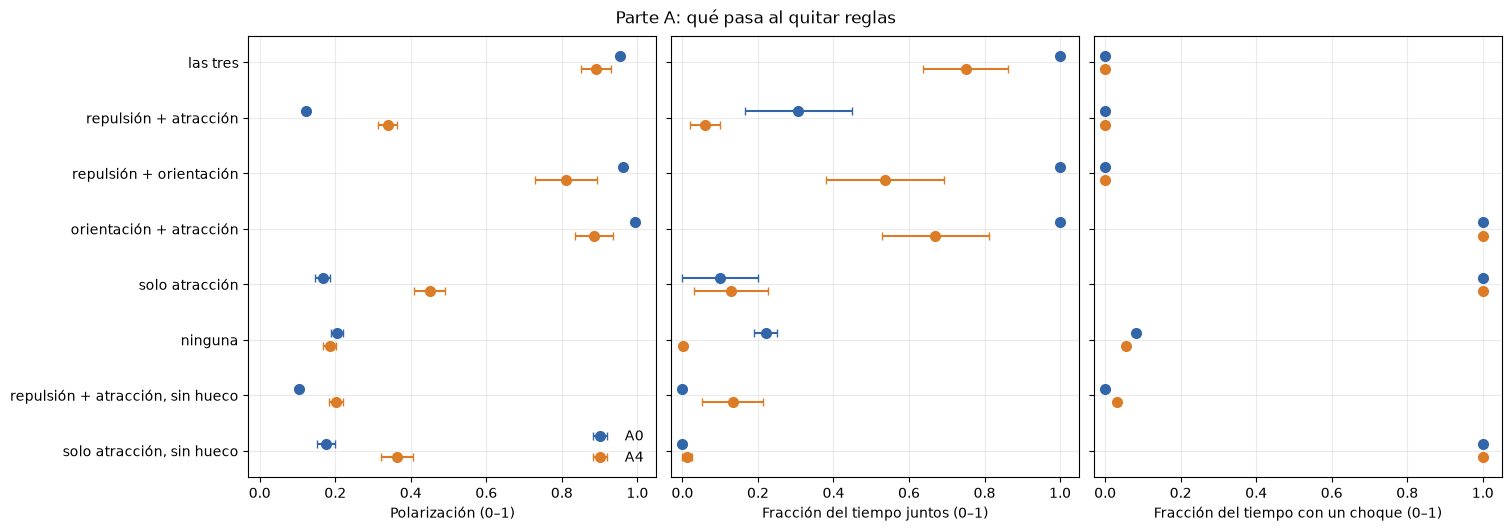

In [6]:
FIGURE_A_TITLE = "Parte A: qué pasa al quitar reglas"

rule_order = []
for settings in rule_runs + no_gap_runs:
    if settings["rule_set"] not in rule_order:
        rule_order.append(settings["rule_set"])
panels = [
    ("polarization", "Polarización (0–1)"),
    ("together_fraction", "Fracción del tiempo juntos (0–1)"),
    ("collision_fraction", "Fracción del tiempo con un choque (0–1)"),
]
BASE_COLORS = {"A0": A0_COLOR, "A4": PUCKETT_COLOR}
OFFSETS = {"A0": -0.12, "A4": 0.12}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True, constrained_layout=True)
for axis, (column, axis_label) in zip(axes, panels):
    for base in ["A0", "A4"]:
        positions = []
        means = []
        errors = []
        for index in range(len(rule_order)):
            row = rules_summary[(rules_summary["base"] == base) & (rules_summary["rule_set"] == rule_order[index])]
            positions.append(index + OFFSETS[base])
            means.append(row[column].iloc[0])
            errors.append(row[column + "_se"].iloc[0])
        axis.errorbar(means, positions, xerr=errors, color=BASE_COLORS[base], marker="o",
                      markersize=7, linestyle="none", capsize=3, label=base)
    axis.set_xlim(-0.03, 1.05)
    axis.set_xlabel(axis_label)
    axis.grid(alpha=0.25)
axes[0].set_yticks(list(range(len(rule_order))))
axes[0].set_yticklabels(rule_order)
axes[0].invert_yaxis()
axes[0].legend(frameon=False, loc="lower right")
fig.suptitle(FIGURE_A_TITLE)
fig.savefig(FIGURE_FOLDER / "part_a_rules.png", dpi=150)
plt.show()

## Parte B — Sensibilidad: un parámetro a la vez

Base: A4 (Puckett) con 20 peces y 1 BL/s. Cambiamos un solo parámetro y dejamos el resto igual. El valor base de cada parámetro se corre una sola vez (fila "base") y se usa en todos los rangos.

In [7]:
SENSITIVITY = [
    ("r_r (BL)", "repulsion_radius", [0.25, 0.5, 0.75, 1.0]),
    ("r_o (BL)", "orientation_radius", [0.55, 1.0, 2.0, 3.0, 4.0, 5.0]),
    ("r_a (BL)", "attraction_radius", [3.5, 4.5, 5.5, 7.0, 9.0]),
    ("campo visual (°)", "fov_degrees", [180.0, 230.0, 270.0, 320.0, 360.0]),
    ("giro máx. (rad/decisión)", "turn_per_decision", [0.25, 0.5, 1.0, 1.75, None]),
    ("ruido (rad/decisión)", "noise_per_decision", [0.0, 0.01, 0.05, 0.1, 0.2]),
    ("N (peces)", "n_fish", [10, 20, 40, 80]),
]


def value_text(value):
    """How a parameter value is written in tables: None means no turn limit."""
    if value is None:
        return "sin límite"
    return f"{value:g}"


base_run = change_settings(PUCKETT_SETTINGS, "base (A4)", {})
base_run["parameter"] = "base"
base_run["value"] = "base"

sensitivity_runs = [base_run]
for name, key, values in SENSITIVITY:
    for value in values:
        if value == PUCKETT_SETTINGS[key]:
            continue   # the base run already covers this value
        settings = change_settings(PUCKETT_SETTINGS, f"{name} = {value_text(value)}", {key: value})
        settings["parameter"] = name
        settings["value"] = value_text(value)
        sensitivity_runs.append(settings)

print(len(sensitivity_runs), "configurations (including the base)")

28 configurations (including the base)


Corremos las configuraciones con 10 seeds. Las de 80 peces son las más lentas.

In [8]:
sensitivity_results = run_many(sensitivity_runs, SEEDS, DATA_FOLDER / "part_b_sensitivity.csv")
sensitivity_summary = summarize(sensitivity_results, ["label", "parameter", "value"])

Loaded saved results from part_b_sensitivity.csv (set study_tools.RERUN = True to simulate again).


### ℓ (del estudio 3) y tamaño de arena (del estudio 2)

El README pide tomar estos dos rangos de los otros estudios, que usan la misma base y las mismas seeds:

- **ℓ:** las corridas A4 del estudio 3 dentro del rango de la luz (0.025–0.625 BL por decisión);
- **arena:** las corridas del estudio 2 con arena de 20, 28 y 40 BL.

Como comprobación, la corrida A4 con ℓ = 0.125 del estudio 3 tiene que dar exactamente lo mismo que nuestra base.

In [9]:
STUDY_3_CSV = TOOLS_FOLDER / "03_dt_y_velocidad" / "data" / "part_b_step_length.csv"
STUDY_2_CSV = TOOLS_FOLDER / "02_parametros_nuevos" / "data" / "results.csv"

borrowed = []

# Step length from study 3: A4 runs inside the light range.
if STUDY_3_CSV.exists():
    study_3 = study_tools.load_results(STUDY_3_CSV)
    study_3 = study_3[(study_3["base"] == "A4") & (study_3["step_length"] >= 0.025) & (study_3["step_length"] <= 0.625)].copy()
    # Consistency check: l = 0.125 in study 3 is exactly our base run.
    same = study_3[study_3["step_length"] == 0.125].sort_values("seed")["polarization"].to_numpy()
    ours = sensitivity_results[sensitivity_results["label"] == "base (A4)"].sort_values("seed")["polarization"].to_numpy()
    assert np.array_equal(same, ours), "study 3 and study 4 disagree on the base run"
    print("Check passed: study 3 (l = 0.125) = study 4 base, seed by seed.")
    study_3 = study_3[study_3["step_length"] != 0.125]
    study_3["parameter"] = "ℓ (BL/decisión)"
    study_3["value"] = study_3["step_length"].map(value_text)
    study_3["label"] = "ℓ (BL/decisión) = " + study_3["value"]
    borrowed.append(study_3)
else:
    print("Study 3 results not found yet:", STUDY_3_CSV)

# Arena size from study 2.
if STUDY_2_CSV.exists():
    study_2 = study_tools.load_results(STUDY_2_CSV)
    study_2 = study_2[study_2["parameter"] == "tamaño de arena"].copy()
    study_2["parameter"] = "arena (BL)"
    study_2["label"] = "arena (BL) = " + study_2["value"].astype(str)
    borrowed.append(study_2)
else:
    print("Study 2 results not found yet:", STUDY_2_CSV)

sensitivity_all = pd.concat([sensitivity_results] + borrowed, ignore_index=True)
sensitivity_all_summary = summarize(sensitivity_all, ["label", "parameter", "value"])
print(sensitivity_all_summary["parameter"].unique())

Check passed: study 3 (l = 0.125) = study 4 base, seed by seed.
<StringArray>
['base', 'r_r (BL)', 'r_o (BL)', 'r_a (BL)', 'campo visual (°)', 'giro máx. (rad/decisión)', 'ruido (rad/decisión)', 'N (peces)', 'ℓ (BL/decisión)', 'arena (BL)']
Length: 10, dtype: str


### Resultados de la parte B

Una tabla por parámetro (la base aparece en cada una).

In [10]:
def parameter_names(summary):
    """The parameters in a summary, in the order in which they were run (without the base)."""
    names = []
    for parameter in summary["parameter"]:
        if parameter != "base" and parameter not in names:
            names.append(parameter)
    return names


# The base value of every parameter, to write it in the tables and the figures.
BASE_VALUES = {"ℓ (BL/decisión)": "0.125", "arena (BL)": "28"}
for name, key, values in SENSITIVITY:
    BASE_VALUES[name] = value_text(PUCKETT_SETTINGS[key])


def rows_for(summary, parameter):
    """The summary rows of one parameter, with the base row included."""
    base_row = summary[summary["parameter"] == "base"].copy()
    base_row["value"] = BASE_VALUES[parameter] + " (base)"
    rows = summary[summary["parameter"] == parameter]
    return pd.concat([base_row, rows], ignore_index=True)


for parameter in parameter_names(sensitivity_all_summary):
    print(parameter)
    display(short_table(rows_for(sensitivity_all_summary, parameter)))

r_r (BL)


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,base (A4),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,r_r (BL) = 0.25,3/10,0.91 ± 0.04,0.25 ± 0.08,0.43 ± 0.06,0.70 ± 0.13,0.05 ± 0.00,0.05 ± 0.01
2,r_r (BL) = 0.75,8/10,0.69 ± 0.01,0.13 ± 0.03,0.91 ± 0.11,0.92 ± 0.07,0.00 ± 0.00,0.48 ± 0.01
3,r_r (BL) = 1,0/10,0.21 ± 0.01,0.11 ± 0.01,1.01 ± 0.05,0.94 ± 0.06,0.00 ± 0.00,0.63 ± 0.02


r_o (BL)


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,base (A4),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,r_o (BL) = 0.55,0/10,0.18 ± 0.01,0.11 ± 0.01,1.32 ± 0.11,0.35 ± 0.14,0.05 ± 0.01,0.13 ± 0.02
2,r_o (BL) = 1,0/10,0.22 ± 0.02,0.15 ± 0.02,1.03 ± 0.12,0.35 ± 0.15,0.04 ± 0.01,0.18 ± 0.01
3,r_o (BL) = 2,0/10,0.57 ± 0.02,0.12 ± 0.02,0.65 ± 0.06,0.91 ± 0.07,0.01 ± 0.00,0.21 ± 0.01
4,r_o (BL) = 4,9/10,0.94 ± 0.04,0.11 ± 0.08,0.61 ± 0.02,0.90 ± 0.10,0.00 ± 0.00,0.29 ± 0.01
5,r_o (BL) = 5,10/10,0.99 ± 0.00,0.04 ± 0.01,0.66 ± 0.02,1.00 ± 0.00,0.00 ± 0.00,0.31 ± 0.01


r_a (BL)


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,base (A4),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,r_a (BL) = 3.5,5/10,0.89 ± 0.04,0.33 ± 0.10,0.69 ± 0.03,0.50 ± 0.17,0.00 ± 0.00,0.28 ± 0.01
2,r_a (BL) = 4.5,8/10,0.94 ± 0.03,0.15 ± 0.09,0.73 ± 0.13,0.80 ± 0.13,0.00 ± 0.00,0.28 ± 0.02
3,r_a (BL) = 7,10/10,0.98 ± 0.00,0.02 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.30 ± 0.01
4,r_a (BL) = 9,9/10,0.93 ± 0.05,0.10 ± 0.07,0.58 ± 0.00,0.90 ± 0.10,0.00 ± 0.00,0.27 ± 0.01


... (8 outputs left out)

ℓ (BL/decisión)


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,base (A4),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,ℓ (BL/decisión) = 0.025,8/10,0.96 ± 0.02,0.15 ± 0.09,0.65 ± 0.10,0.89 ± 0.10,0.00 ± 0.00,0.46 ± 0.00
2,ℓ (BL/decisión) = 0.05,10/10,0.99 ± 0.00,0.02 ± 0.00,0.54 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.41 ± 0.00
3,ℓ (BL/decisión) = 0.1,8/10,0.90 ± 0.06,0.11 ± 0.06,0.57 ± 0.00,0.84 ± 0.11,0.00 ± 0.00,0.32 ± 0.01
4,ℓ (BL/decisión) = 0.2,7/10,0.86 ± 0.05,0.19 ± 0.08,0.69 ± 0.06,0.76 ± 0.12,0.02 ± 0.00,0.15 ± 0.01
5,ℓ (BL/decisión) = 0.25,3/10,0.83 ± 0.06,0.19 ± 0.08,0.67 ± 0.02,0.74 ± 0.14,0.05 ± 0.01,0.11 ± 0.02
6,ℓ (BL/decisión) = 0.375,0/10,0.83 ± 0.05,0.19 ± 0.07,0.87 ± 0.10,0.80 ± 0.13,0.14 ± 0.02,0.03 ± 0.01
7,ℓ (BL/decisión) = 0.5,0/10,0.76 ± 0.01,0.19 ± 0.03,1.11 ± 0.10,0.89 ± 0.05,0.34 ± 0.03,0.04 ± 0.01
8,ℓ (BL/decisión) = 0.625,0/10,0.69 ± 0.02,0.17 ± 0.02,0.98 ± 0.04,0.76 ± 0.08,0.42 ± 0.04,0.02 ± 0.00


arena (BL)


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,base (A4),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,arena (BL) = 20,9/10,0.96 ± 0.01,0.04 ± 0.01,0.60 ± 0.02,0.99 ± 0.01,0.00 ± 0.00,0.27 ± 0.01
2,arena (BL) = 40,4/10,0.86 ± 0.04,0.26 ± 0.08,0.73 ± 0.13,0.53 ± 0.15,0.00 ± 0.00,0.28 ± 0.01


### ¿Qué tan sensible es cada parámetro? (criterio del README, fijado antes de correr)

Para cada parámetro buscamos el cambio más grande de cada métrica dentro de su rango (máximo menos mínimo de las medias):

- **métricas de 0 a 1:** polarización, rotación, fracción del grupo más grande y fracción del tiempo con un choque;
- **distancias:** distancia al vecino más cercano y distancia al centro, como cambio relativo al valor de la base;
- **"cambia el resultado":** en algún valor el cardumen funciona en más de la mitad de las seeds y en otro no.

| Clase | Criterio |
|---|---|
| muy sensible | cambia el resultado, o una métrica de 0 a 1 cambia más de 0.2, o una distancia más del 40 % |
| algo sensible | el cambio más grande está entre 0.05 y 0.2 (distancias: entre 10 % y 40 %) |
| poco sensible | menos de 0.05 (distancias: menos de 10 %) |

In [11]:
UNIT_METRICS = ["polarization", "rotation", "largest_group_fraction", "collision_fraction"]
DISTANCE_METRICS = ["nnd", "centroid_distance"]


def sensitivity_of(summary, parameter):
    """The largest change of every metric inside the range of one parameter."""
    rows = rows_for(summary, parameter)
    base_row = summary[summary["parameter"] == "base"].iloc[0]
    result = {"parameter": parameter}

    # Does the verdict "works in more than half of the seeds" change inside the range?
    works_somewhere = (rows["works"] > 0.5).any()
    fails_somewhere = (rows["works"] <= 0.5).any()
    result["verdict changes"] = works_somewhere and fails_somewhere

    for metric in UNIT_METRICS:
        result[metric] = rows[metric].max() - rows[metric].min()
    for metric in DISTANCE_METRICS:
        result[metric + " (relative)"] = (rows[metric].max() - rows[metric].min()) / base_row[metric]
    return result


def sensitivity_class(result):
    """Very / somewhat / not very sensitive, with the README thresholds."""
    largest_unit_change = 0.0
    for metric in UNIT_METRICS:
        largest_unit_change = max(largest_unit_change, result[metric])
    largest_distance_change = 0.0
    for metric in DISTANCE_METRICS:
        largest_distance_change = max(largest_distance_change, result[metric + " (relative)"])

    if result["verdict changes"] or largest_unit_change > 0.2 or largest_distance_change > 0.4:
        return "muy sensible"
    if largest_unit_change >= 0.05 or largest_distance_change >= 0.1:
        return "algo sensible"
    return "poco sensible"


def sensitivity_table_for(summary):
    """One row per parameter: its largest changes and its class."""
    rows = []
    for parameter in parameter_names(summary):
        result = sensitivity_of(summary, parameter)
        result["class"] = sensitivity_class(result)
        rows.append(result)
    return pd.DataFrame(rows)


sensitivity_table = sensitivity_table_for(sensitivity_all_summary)
sensitivity_table

,parameter,verdict changes,polarization,rotation,largest_group_fraction,collision_fraction,nnd (relative),centroid_distance (relative),class
0,r_r (BL),True,0.705,0.146,0.067,5.208e-02,0.963,0.304,muy sensible
1,r_o (BL),True,0.805,0.110,0.282,5.188e-02,1.191,1.354,muy sensible
2,r_a (BL),True,0.093,0.311,0.092,6.250e-04,0.247,0.852,muy sensible
3,campo visual (°),True,0.225,0.364,0.155,8.333e-04,1.432,1.122,muy sensible
4,giro máx. (rad/decisión),True,0.075,0.121,0.071,5.188e-02,0.151,0.469,muy sensible
5,ruido (rad/decisión),False,0.050,0.086,0.062,4.167e-04,0.163,0.580,muy sensible
6,N (peces),True,0.847,0.086,0.062,5.813e-01,0.322,0.495,muy sensible
7,ℓ (BL/decisión),True,0.300,0.173,0.103,4.208e-01,0.943,0.813,muy sensible
8,arena (BL),True,0.097,0.218,0.153,4.167e-04,0.221,1.336,muy sensible


**Todos los parámetros salen "muy sensibles".** No es que todo importe igual: la base A4 está **justo en el borde**. Funciona en 6 de 10 seeds, y las 4 que fallan es porque en 180 BL de nado el grupo todavía no se juntó en la arena de 28 BL (en el estudio 2, con el triple de tiempo, las 10 funcionan). Cualquier cambio que acelere o frene un poco el momento en que se juntan cambia el veredicto y la distancia al centro. Por eso, con esta base, el criterio mide sobre todo **cuánto tarda el grupo en juntarse**.

No cambiamos el criterio (regla 5). Lo reportamos así y, como **extra**, repetimos la sensibilidad con el grupo ya junto (parte B2, abajo).

### Figura B — Gráfico tornado (base A4, inicio al azar)

Una barra por parámetro: va desde la polarización más baja hasta la más alta dentro de su rango (izquierda) y lo mismo para la distancia al vecino más cercano (derecha). La línea negra es la base. Ordenadas de la que más cambia a la que menos; el color es la clase de sensibilidad. En cada punta está el valor del parámetro que da ese resultado.

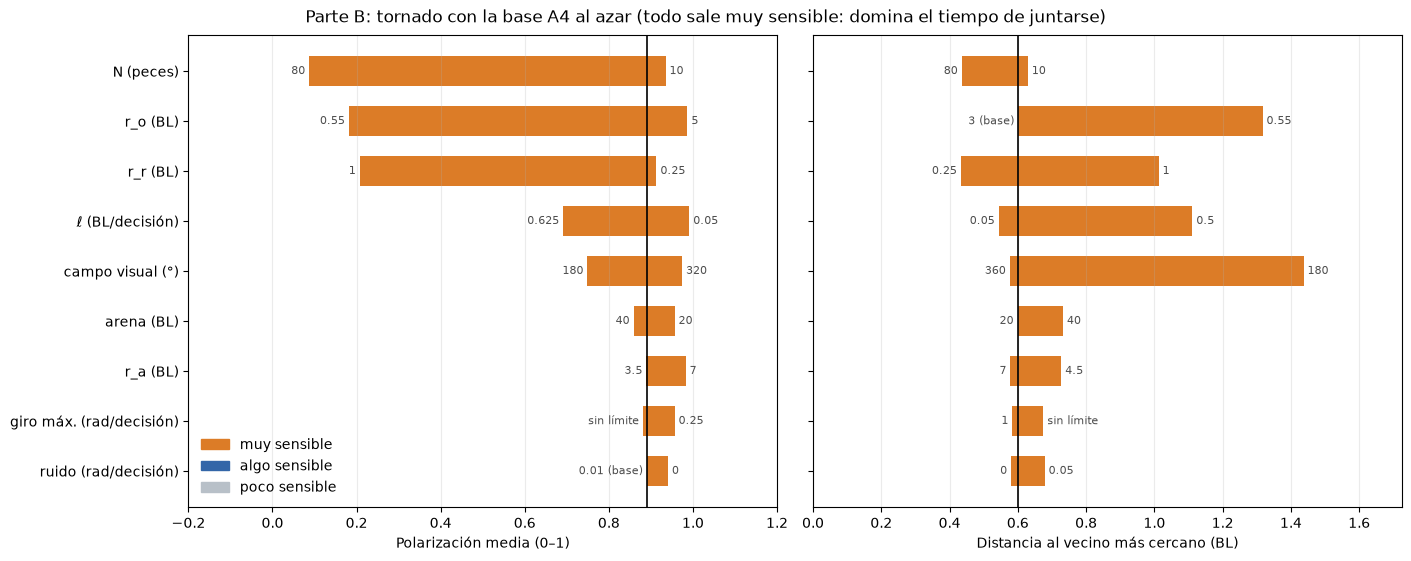

In [12]:
from matplotlib.patches import Patch

CLASS_COLORS = {"muy sensible": PUCKETT_COLOR, "algo sensible": A0_COLOR, "poco sensible": "#b8c0c8"}


def plot_tornado(summary, table, title, file_name):
    """Tornado plot: for each parameter, the range of polarization and of NND inside its range."""
    parameters = parameter_names(summary)
    base_row = summary[summary["parameter"] == "base"].iloc[0]

    # Order: the widest polarization range at the top.
    widths = []
    for parameter in parameters:
        rows = rows_for(summary, parameter)
        widths.append(rows["polarization"].max() - rows["polarization"].min())
    order = list(np.argsort(widths))   # smallest first, so the widest ends up at the top

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True, constrained_layout=True)
    for axis, metric, axis_label in [(axes[0], "polarization", "Polarización media (0–1)"),
                                     (axes[1], "nnd", "Distancia al vecino más cercano (BL)")]:
        for position, index in enumerate(order):
            parameter = parameters[index]
            rows = rows_for(summary, parameter)
            low = rows[metric].min()
            high = rows[metric].max()
            parameter_class = table[table["parameter"] == parameter]["class"].iloc[0]
            axis.barh(position, high - low, left=low, height=0.6, color=CLASS_COLORS[parameter_class])
            # Write which value gives the lowest and the highest result.
            low_value = rows.loc[rows[metric].idxmin(), "value"]
            high_value = rows.loc[rows[metric].idxmax(), "value"]
            axis.text(low, position, f"{low_value} ", ha="right", va="center", fontsize=8, color="0.3")
            axis.text(high, position, f" {high_value}", ha="left", va="center", fontsize=8, color="0.3")
        axis.axvline(base_row[metric], color="black", linewidth=1.2)
        axis.set_xlabel(axis_label)
        axis.grid(alpha=0.25, axis="x")
    axes[0].set_xlim(-0.2, 1.2)
    largest_nnd = summary["nnd"].max()
    axes[1].set_xlim(0, largest_nnd * 1.2)
    labels = []
    for index in order:
        labels.append(parameters[index])
    axes[0].set_yticks(list(range(len(order))))
    axes[0].set_yticklabels(labels)
    # One coloured square per class for the legend.
    legend_squares = []
    for parameter_class in CLASS_COLORS:
        legend_squares.append(Patch(color=CLASS_COLORS[parameter_class], label=parameter_class))
    axes[0].legend(handles=legend_squares, frameon=False, loc="lower left")
    fig.suptitle(title)
    fig.savefig(FIGURE_FOLDER / file_name, dpi=150)
    plt.show()


plot_tornado(sensitivity_all_summary, sensitivity_table,
             "Parte B: tornado con la base A4 al azar (todo sale muy sensible: domina el tiempo de juntarse)",
             "part_b_tornado.png")

## Parte B2 (extra, no está en el README) — Sensibilidad con el grupo ya junto

En la fase de luz vamos a empezar con el cardumen **ya formado** (checkpoints, como en Trial Two). Entonces la pregunta útil es: *una vez que el grupo está junto, ¿qué parámetros cambian cómo se comporta?*

Repetimos la parte B con la misma base A4, pero con **inicio compacto** (los peces empiezan en el cuadrado central, de lado 25 % de la arena; en el estudio 2 así funcionan las 10 seeds). Agregamos también ℓ (vía la velocidad, con dt = 0.125 s) y el tamaño de arena. El criterio de clases es **el mismo** de arriba.

In [13]:
COMPACT_BASE = change_settings(PUCKETT_SETTINGS, "base compacta (A4)", {"initial_spread": 0.25})
LIGHT_STEP_LENGTHS = [0.025, 0.05, 0.1, 0.2, 0.25, 0.375, 0.5, 0.625]
ARENA_SIZES = [20.0, 40.0]


def one_change(name, key, value, value_label):
    """The compact base with one parameter changed."""
    settings = change_settings(COMPACT_BASE, f"{name} = {value_label}", {key: value})
    settings["parameter"] = name
    settings["value"] = value_label
    return settings


compact_base_run = change_settings(COMPACT_BASE, "base compacta (A4)", {})
compact_base_run["parameter"] = "base"
compact_base_run["value"] = "base"

compact_runs = [compact_base_run]
for name, key, values in SENSITIVITY:
    for value in values:
        if value == PUCKETT_SETTINGS[key]:
            continue   # the base run already covers this value
        compact_runs.append(one_change(name, key, value, value_text(value)))
for step_length in LIGHT_STEP_LENGTHS:
    compact_runs.append(one_change("ℓ (BL/decisión)", "speed", step_length / 0.125, value_text(step_length)))
for arena in ARENA_SIZES:
    compact_runs.append(one_change("arena (BL)", "arena", arena, value_text(arena)))

print(len(compact_runs), "configurations (including the base)")

38 configurations (including the base)


Corremos las configuraciones con 10 seeds.

In [14]:
compact_results = run_many(compact_runs, SEEDS, DATA_FOLDER / "part_b2_sensitivity_compact.csv")
compact_summary = summarize(compact_results, ["label", "parameter", "value"])

for parameter in parameter_names(compact_summary):
    print(parameter)
    display(short_table(rows_for(compact_summary, parameter)))

Loaded saved results from part_b2_sensitivity_compact.csv (set study_tools.RERUN = True to simulate again).
r_r (BL)


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,base compacta (A4),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,r_r (BL) = 0.25,3/10,0.98 ± 0.00,0.03 ± 0.00,0.34 ± 0.00,1.00 ± 0.00,0.06 ± 0.00,0.05 ± 0.01
2,r_r (BL) = 0.75,10/10,0.69 ± 0.01,0.08 ± 0.00,0.78 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.46 ± 0.01
3,r_r (BL) = 1,0/10,0.20 ± 0.00,0.10 ± 0.00,0.95 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.60 ± 0.02


r_o (BL)


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,base compacta (A4),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,r_o (BL) = 0.55,0/10,0.15 ± 0.00,0.10 ± 0.00,1.31 ± 0.10,0.46 ± 0.10,0.07 ± 0.01,0.12 ± 0.01
2,r_o (BL) = 1,0/10,0.16 ± 0.00,0.10 ± 0.00,0.87 ± 0.05,0.68 ± 0.09,0.06 ± 0.01,0.10 ± 0.02
3,r_o (BL) = 2,1/10,0.59 ± 0.03,0.14 ± 0.02,0.73 ± 0.09,0.97 ± 0.03,0.01 ± 0.00,0.22 ± 0.01
4,r_o (BL) = 4,10/10,0.99 ± 0.00,0.02 ± 0.00,0.58 ± 0.01,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
5,r_o (BL) = 5,10/10,0.99 ± 0.00,0.03 ± 0.00,0.61 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.30 ± 0.01


r_a (BL)


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,base compacta (A4),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,r_a (BL) = 3.5,10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
2,r_a (BL) = 4.5,10/10,0.97 ± 0.01,0.07 ± 0.04,0.67 ± 0.09,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
3,r_a (BL) = 7,10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
4,r_a (BL) = 9,10/10,0.98 ± 0.00,0.04 ± 0.01,0.61 ± 0.03,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01


... (8 outputs left out)

ℓ (BL/decisión)


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,base compacta (A4),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,ℓ (BL/decisión) = 0.025,10/10,1.00 ± 0.00,0.02 ± 0.00,0.53 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.46 ± 0.00
2,ℓ (BL/decisión) = 0.05,10/10,0.99 ± 0.00,0.02 ± 0.00,0.54 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.42 ± 0.00
3,ℓ (BL/decisión) = 0.1,10/10,0.99 ± 0.00,0.02 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.33 ± 0.01
4,ℓ (BL/decisión) = 0.2,10/10,0.96 ± 0.00,0.04 ± 0.00,0.61 ± 0.00,1.00 ± 0.00,0.02 ± 0.00,0.16 ± 0.01
5,ℓ (BL/decisión) = 0.25,2/10,0.94 ± 0.01,0.05 ± 0.01,0.64 ± 0.03,1.00 ± 0.00,0.07 ± 0.01,0.08 ± 0.01
6,ℓ (BL/decisión) = 0.375,0/10,0.85 ± 0.01,0.16 ± 0.03,1.00 ± 0.11,0.96 ± 0.04,0.21 ± 0.02,0.04 ± 0.01
7,ℓ (BL/decisión) = 0.5,0/10,0.77 ± 0.02,0.18 ± 0.05,0.90 ± 0.09,0.85 ± 0.11,0.32 ± 0.03,0.03 ± 0.00
8,ℓ (BL/decisión) = 0.625,0/10,0.68 ± 0.01,0.20 ± 0.03,1.05 ± 0.11,0.70 ± 0.11,0.39 ± 0.04,0.03 ± 0.00


arena (BL)


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,base compacta (A4),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,arena (BL) = 20,10/10,0.97 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.27 ± 0.01
2,arena (BL) = 40,10/10,0.98 ± 0.00,0.02 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01


### Clases de sensibilidad con el grupo ya junto (mismo criterio)

In [15]:
compact_table = sensitivity_table_for(compact_summary)
compact_table

,parameter,verdict changes,polarization,rotation,largest_group_fraction,collision_fraction,nnd (relative),centroid_distance (relative),class
0,r_r (BL),True,0.786,0.075,3.542e-04,5.833e-02,1.046,0.838,muy sensible
1,r_o (BL),True,0.838,0.114,8.614e-02,6.896e-02,1.249,0.796,muy sensible
2,r_a (BL),False,0.009,0.049,5.000e-03,6.250e-04,0.153,0.109,algo sensible
3,campo visual (°),True,0.238,0.410,2.169e-01,6.250e-04,1.773,3.757,muy sensible
4,giro máx. (rad/decisión),False,0.008,0.021,4.677e-03,4.396e-02,0.110,0.074,algo sensible
5,ruido (rad/decisión),False,0.042,0.020,3.542e-04,4.167e-04,0.048,0.090,poco sensible
6,N (peces),True,0.905,0.041,3.542e-04,5.842e-01,0.307,0.789,muy sensible
7,ℓ (BL/decisión),True,0.316,0.179,4.953e-02,3.896e-01,0.895,1.507,muy sensible
8,arena (BL),False,0.010,0.007,3.542e-04,2.083e-04,0.011,0.028,poco sensible


### Figura B2 — Tornado con el grupo ya junto

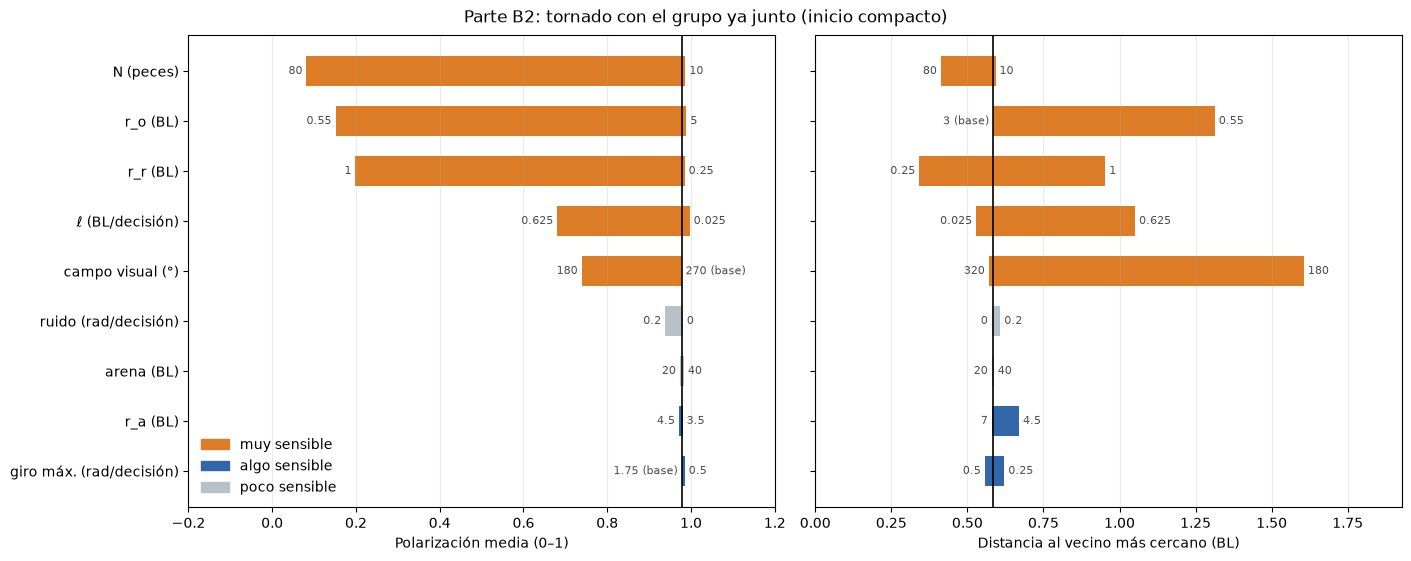

In [16]:
plot_tornado(compact_summary, compact_table,
             "Parte B2: tornado con el grupo ya junto (inicio compacto)",
             "part_b2_tornado_compact.png")

## Parte C — El modelo mínimo

**De la parte A (reglas):** sin repulsión los peces se enciman (choques todo el tiempo) y sin orientación no hay orden. La atracción es la duda: sin ella, A0 igual funciona en 10/10 y A4 en 5/10 (con ella, 6/10).

**De la parte B2 (grupo ya junto):**

- **Muy sensibles** (hay que elegirlos con cuidado): r_r, r_o y N (los tres por la misma razón, ver parte D), el campo visual (solo cuando baja a 180°) y ℓ (desde 0.25 BL hay choques).
- **Algo sensibles:** r_a (cambia un poco la distancia al vecino) y el giro máximo (solo con 0.25 rad aparecen algunos choques).
- **Poco sensibles:** el ruido (0 a 0.2 rad) y el tamaño de arena (20 a 40 BL).

**Modelo mínimo propuesto:** las tres reglas; r_r = 0.5, r_o = 3 y r_a = 5.5 BL (los valores de los papers); 20 peces; ℓ = 0.125 BL (1 BL/s con 8 decisiones por segundo); arena de 28 BL (Puckett). Lo poco sensible, en su valor más simple: **360°, giro de golpe y sin ruido**. Empieza con el grupo junto (inicio compacto), como empezaremos en la fase de luz.

Lo comprobamos con **10 seeds nuevas (10–19)**, junto con el modelo completo de Puckett y dos pruebas sobre la atracción.

In [17]:
NEW_SEEDS = list(range(10, 20))

minimal = change_settings(A0_SETTINGS, "mínimo (3 reglas, 360°, giro de golpe, sin ruido)",
                          {"arena": 28.0, "initial_spread": 0.25})

minimal_runs = [
    change_settings(PUCKETT_SETTINGS, "Puckett completo (A4), inicio compacto", {"initial_spread": 0.25}),
    minimal,
    change_settings(minimal, "mínimo, inicio al azar", {"initial_spread": 1.0}),
    change_settings(minimal, "mínimo sin atracción", {"rules": "repulsion+orientation"}),
    change_settings(PUCKETT_SETTINGS, "Puckett sin atracción, inicio compacto, 540 BL",
                    {"initial_spread": 0.25, "rules": "repulsion+orientation", "swim_distance": 540.0}),
    change_settings(PUCKETT_SETTINGS, "Puckett completo, inicio compacto, 540 BL",
                    {"initial_spread": 0.25, "swim_distance": 540.0}),
]
for settings in minimal_runs:
    print(settings["label"])

Puckett completo (A4), inicio compacto
mínimo (3 reglas, 360°, giro de golpe, sin ruido)
mínimo, inicio al azar
mínimo sin atracción
Puckett sin atracción, inicio compacto, 540 BL
Puckett completo, inicio compacto, 540 BL


Corremos las 6 configuraciones con las seeds nuevas 10–19.

In [18]:
minimal_results = run_many(minimal_runs, NEW_SEEDS, DATA_FOLDER / "part_c_minimal_model.csv")
minimal_summary = summarize(minimal_results, "label")
short_table(minimal_summary)

Loaded saved results from part_c_minimal_model.csv (set study_tools.RERUN = True to simulate again).


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,"Puckett completo (A4), inicio compacto",10/10,0.98 ± 0.00,0.02 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
1,"mínimo (3 reglas, 360°, giro de golpe, sin ruido)",10/10,0.97 ± 0.00,0.02 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
2,"mínimo, inicio al azar",6/10,0.87 ± 0.06,0.15 ± 0.07,0.58 ± 0.01,0.78 ± 0.12,0.00 ± 0.00,0.29 ± 0.01
3,mínimo sin atracción,10/10,0.98 ± 0.00,0.02 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
4,"Puckett sin atracción, inicio compacto, 540 BL",10/10,0.98 ± 0.00,0.02 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.26 ± 0.01
5,"Puckett completo, inicio compacto, 540 BL",10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.27 ± 0.00


In [19]:
final_label_counts(minimal_results)

label_final,polarized,milling,swarm,fragmented
label,,,,
"Puckett completo (A4), inicio compacto",10,0,0,0
"mínimo (3 reglas, 360°, giro de golpe, sin ruido)",10,0,0,0
"mínimo, inicio al azar",6,0,0,4
mínimo sin atracción,10,0,0,0
"Puckett sin atracción, inicio compacto, 540 BL",10,0,0,0
"Puckett completo, inicio compacto, 540 BL",10,0,0,0


## Parte D (extra, no está en el README) — Una sola regla para r_r, r_o y N

¿Por qué r_r, r_o y N son tan sensibles, y por qué de la misma manera? Una idea simple:

- La atracción junta al grupo hasta que su diámetro es más o menos **r_o** (si un pez tiene vecinos más lejos que r_o, la atracción lo acerca).
- En un círculo de diámetro r_o caben como máximo unos **0.9 × (r_o / r_r)²** peces sin que ninguno entre en la zona de repulsión de otro (empaquetados como un panal: cada pez ocupa (√3/2)·r_r²).
- Si hay más peces que eso, siempre hay alguno en la zona de repulsión. Como la repulsión tiene prioridad, ese pez deja de alinearse, y el grupo se vuelve un *swarm*.

Llamamos **apiñamiento** a N dividido por esa capacidad. Con r_r = 0.5 y r_o = 3 BL la capacidad es de unos **33 peces**. Si la idea es correcta, todas las corridas de la parte B2 donde cambia r_r, r_o o N deberían caer sobre **una sola curva**.

In [20]:
def capacity(orientation_radius, repulsion_radius):
    """How many fish fit in a circle of diameter r_o with spacing r_r (hexagonal packing)."""
    return np.pi / (2 * np.sqrt(3)) * (orientation_radius / repulsion_radius) ** 2


# Mean of every configuration of part B2, with its crowding number.
crowding_summary = summarize(compact_results, ["label", "parameter", "n_fish", "repulsion_radius", "orientation_radius"])
crowding_summary["crowding"] = crowding_summary["n_fish"] / capacity(crowding_summary["orientation_radius"],
                                                                     crowding_summary["repulsion_radius"])
crowding_rows = crowding_summary[crowding_summary["parameter"].isin(["base", "r_r (BL)", "r_o (BL)", "N (peces)"])]
crowding_rows[["label", "n_fish", "repulsion_radius", "orientation_radius", "crowding", "polarization", "nnd"]].sort_values("crowding")

,label,n_fish,repulsion_radius,orientation_radius,crowding,polarization,nnd
1,r_r (BL) = 0.25,20,0.25,3.00,0.153,0.985,0.342
8,r_o (BL) = 5,20,0.50,5.00,0.221,0.989,0.610
25,N (peces) = 10,10,0.50,3.00,0.306,0.987,0.592
7,r_o (BL) = 4,20,0.50,4.00,0.345,0.986,0.585
0,base compacta (A4),20,0.50,3.00,0.613,0.977,0.584
26,N (peces) = 40,40,0.50,3.00,1.225,0.605,0.507
2,r_r (BL) = 0.75,20,0.75,3.00,1.378,0.692,0.780
6,r_o (BL) = 2,20,0.50,2.00,1.378,0.593,0.732
3,r_r (BL) = 1,20,1.00,3.00,2.450,0.199,0.953
27,N (peces) = 80,80,0.50,3.00,2.450,0.082,0.413


### Figura D — El apiñamiento explica r_r, r_o y N a la vez

Cada punto es una configuración de la parte B2 (grupo ya junto, media de 10 seeds). El color dice qué parámetro cambió. La línea vertical es apiñamiento = 1 (N igual a la capacidad).

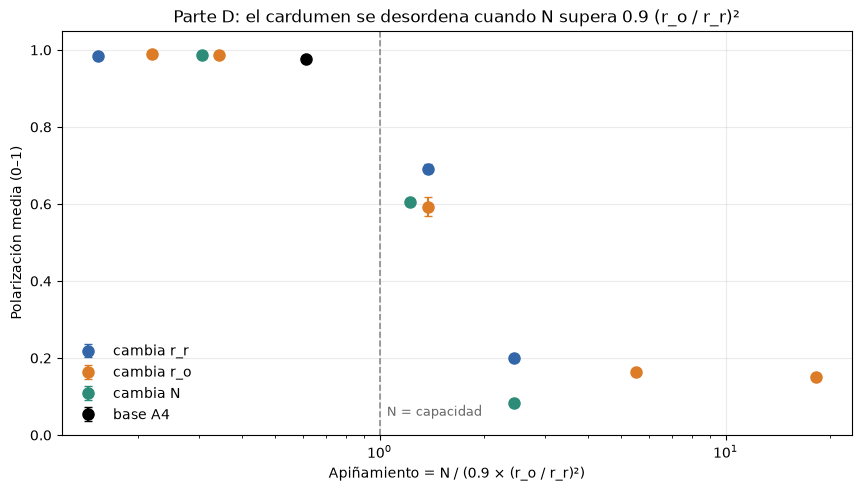

In [21]:
FIGURE_D_TITLE = "Parte D: el cardumen se desordena cuando N supera 0.9 (r_o / r_r)²"

PARAMETER_COLORS = {"r_r (BL)": A0_COLOR, "r_o (BL)": PUCKETT_COLOR, "N (peces)": EXTRA_COLOR, "base": "black"}
PARAMETER_NAMES = {"r_r (BL)": "cambia r_r", "r_o (BL)": "cambia r_o", "N (peces)": "cambia N", "base": "base A4"}

fig, axis = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
axis.axvline(1.0, color="0.55", linestyle="--", linewidth=1.2)
for parameter in ["r_r (BL)", "r_o (BL)", "N (peces)", "base"]:
    rows = crowding_rows[crowding_rows["parameter"] == parameter]
    axis.errorbar(rows["crowding"], rows["polarization"], yerr=rows["polarization_se"],
                  color=PARAMETER_COLORS[parameter], marker="o", markersize=8, linestyle="none",
                  capsize=3, label=PARAMETER_NAMES[parameter])
axis.text(1.05, 0.05, "N = capacidad", color="0.4", fontsize=9)
axis.set_xscale("log")
axis.set_xlabel("Apiñamiento = N / (0.9 × (r_o / r_r)²)")
axis.set_ylabel("Polarización media (0–1)")
axis.set_ylim(0, 1.05)
axis.grid(alpha=0.25)
axis.legend(frameon=False, loc="lower left")
axis.set_title(FIGURE_D_TITLE)
fig.savefig(FIGURE_FOLDER / "part_d_crowding.png", dpi=150)
plt.show()

## Guardar todos los resultados

In [22]:
rules_all["part"] = "A"
sensitivity_results["part"] = "B"
compact_results["part"] = "B2 (extra)"
minimal_results["part"] = "C"
all_results = pd.concat([rules_all, sensitivity_results, compact_results, minimal_results], ignore_index=True)
all_results.to_csv(DATA_FOLDER / "results.csv", index=False)
sensitivity_table.to_csv(DATA_FOLDER / "sensitivity_classes.csv", index=False)
compact_table.to_csv(DATA_FOLDER / "sensitivity_classes_compact.csv", index=False)
print(len(all_results), "simulations saved in data/results.csv")

880 simulations saved in data/results.csv
